# Chapter 53: Aggregate Demand, Consumption, Saving, and Fiscal Multipliers

This notebook reruns four worked examples from the chapter: a temporary bonus against a permanent raise (permanent income), a debt-financed tax cut (Ricardian equivalence), the paradox of thrift and the balanced-budget multiplier. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def smooth_consumption(incomes, r=0.0, floor=None):
    """Equal consumption from the present value of an income stream, with an optional first-period need.

    permanent-income-hypothesis (chapter 53): incomes 40,000 x 4 at r = 0 give 160,000 / 4 = 40,000;
    a 20,000 first-period bonus gives 180,000 / 4 = 45,000 (15,000 of the bonus saved); a permanent
    raise gives 240,000 / 4 = 60,000. With ``floor`` (a first-period need, no borrowing) the household
    spends max(smoothed, floor) now, capped by current income, and smooths the rest over later periods.
    Returns consumption list, saving list (income minus consumption), resources (present value),
    smooth (unconstrained level), constrained (floor raised or capped period-1 spending) and
    shortfall (floor minus period-1 consumption, 0 when met).
    """
    incomes = [float(y) for y in incomes]
    n = len(incomes)
    R = 1.0 + r
    disc = [R ** -t for t in range(n)]
    resources = sum(y * d for y, d in zip(incomes, disc))
    level = resources / sum(disc)
    cons = [level] * n
    constrained = False
    shortfall = 0.0
    if floor is not None and n > 1:
        c0 = min(max(level, float(floor)), incomes[0]) if level < floor else level
        if c0 != level:
            constrained = True
            rest = sum(y * d for y, d in zip(incomes[1:], disc[:-1])) + (incomes[0] - c0) * R
            rest_level = rest / sum(disc[:-1])
            cons = [c0] + [rest_level] * (n - 1)
        shortfall = max(float(floor) - cons[0], 0.0)
    return {"consumption": cons, "saving": [y - c for y, c in zip(incomes, cons)], "resources": resources,
            "smooth": level, "constrained": constrained, "shortfall": shortfall}


def keynesian_cross(a, c, I, G=0.0, T=0.0):
    """Fixed-price demand equilibrium Y = (a - cT + I + G) / (1 - c), with C = a + c(Y - T).

    paradox-of-thrift (chapter 53): a = 20, c = 0.8, I = 80 give Y = 100 / 0.2 = 500, C = 420, S = 80;
    a = 10 gives Y = 450, C = 370, S = 80. balanced-budget-multiplier: dG = dT = 40 at c = 0.75 raises
    Y by 40. Returns Y, C, S (private saving Y - T - C), multiplier 1 / (1 - c).
    """
    Y = (a - c * T + I + G) / (1.0 - c)
    C = a + c * (Y - T)
    return {"Y": Y, "C": C, "S": Y - T - C, "multiplier": 1.0 / (1.0 - c)}


def multiplier_rounds(first, c, n):
    """Spending rounds first, first c, first c^2, ... (n terms).

    balanced-budget-multiplier (chapter 53): 10, 7.5, 5.625, 4.21875, ...; the infinite sum is
    10 / (1 - 0.75) = 40.
    """
    return [first * c ** k for k in range(n)]


def ricardian(cut, r, shift=0.0):
    """Debt-financed tax cut repaid next year with interest, with a desired borrowing shift.

    ricardian-equivalence (chapter 53): cut 1,000 at r = 0.05 means a future tax of 1.05(1,000) = 1,050
    with present value 1,000. Unconstrained, the household saves all 1,000. A household that wanted to
    borrow 400 consumes 400, saves 600, which grows to 1.05(600) = 630, leaving 1,050 - 630 = 420 of
    the later tax (present value 400). Returns future_tax, pv_tax, consumed, saved, saved_grown,
    remaining, remaining_pv.
    """
    R = 1.0 + r
    consumed = min(max(shift, 0.0), cut)
    saved = cut - consumed
    future_tax = R * cut
    grown = R * saved
    remaining = future_tax - grown
    return {"future_tax": future_tax, "pv_tax": future_tax / R, "consumed": consumed, "saved": saved,
            "saved_grown": grown, "remaining": remaining, "remaining_pv": remaining / R}


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(smooth_consumption=smooth_consumption)


macro = SimpleNamespace(keynesian_cross=keynesian_cross, multiplier_rounds=multiplier_rounds, ricardian=ricardian)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'permanent-income-hypothesis': {'income': 40000,
                                 'periods': 4,
                                 'r': 0.0,
                                 'bonus': 20000,
                                 'resources': 160000,
                                 'c_base': 40000,
                                 'resources_bonus': 180000,
                                 'c_bonus': 45000,
                                 'first_change': 5000,
                                 'saved': 15000,
                                 'resources_permanent': 240000,
                                 'c_permanent': 60000,
                                 'need': 50000,
                                 'spend_at_least': 10000},
 'ricardian-equivalence': {'cut': 1000,
                           'r': 0.05,
                           'future_tax': 1050,
                           'pv_tax': 1000,
                           'shift': 400,
                           'saved': 600,
                           'saved_grown': 630,
                           'remaining': 420,
                           'remaining_pv': 400},
 'paradox-of-thrift': {'a': 20,
                       'c': 0.8,
                       'I': 80,
                       'Y': 500,
                       'C': 420,
                       'S': 80,
                       'a_thrift': 10,
                       'C_planned': 410,
                       'S_planned': 90,
                       'Y_thrift': 450,
                       'C_thrift': 370,
                       'S_thrift': 80,
                       'loss': 50,
                       'multiplier': 5},
 'balanced-budget-multiplier': {'c': 0.75,
                                'dG': 40,
                                'tax_first_round': 30,
                                'first_round': 10,
                                'rounds': [10, 7.5, 5.625, 4.21875],
                                'total': 40,
                                'G_effect': 160,
                                'T_effect': -120,
                                'net': 40},
 'constructed': {'permanent-income-hypothesis': {'dY': [10000, 40000]},
                 'ricardian-equivalence': {'r': [0.0, 0.1], 'shift': [800]},
                 'paradox-of-thrift': {'a': [15], 'c': [0.6, 0.75]},
                 'balanced-budget-multiplier': {'c': [0.5, 0.9], 'dG': [20, 80]}}}


def pih_picture(boost=20_000, kind="one", floor="none"):
    base = BV["permanent-income-hypothesis"]["income"]
    incomes = [base + boost] + [base + (boost if kind == "all" else 0)] * 3
    need = None if floor == "none" else float(floor)
    res = choice.smooth_consumption(incomes, 0.0, need)
    cons = res["consumption"]
    c1, later = cons[0], cons[1]
    saved1 = incomes[0] - c1
    fig, ax = new_figure()
    xs = np.arange(1, 5)
    ax.bar(xs, incomes, width=0.6, color=PALETTE["light"], label="income")
    ax.plot(xs, cons, color=PALETTE["navy"], marker="o", linewidth=2.2, label="consumption")
    for x, y, cc in zip(xs, incomes, cons):
        if y - cc > 1e-9:
            ax.vlines(x, cc, y, color=PALETTE["teal"], linewidth=5)
    label(ax, 1, c1, f"C1 = {money(c1, 0)}", col="navy", dx=10, dy=-14, va="top")
    if need is not None:
        hline(ax, need, f"need {money(need, 0)}", col="terracotta", x_frac=0.45, va="bottom")
    ax.legend(loc="upper right", frameon=False)
    ax.set_xticks(xs, [f"Period {i}" for i in xs])
    ax.set_ylim(0, max(incomes) * 1.25)
    ax.yaxis.set_major_formatter(lambda v, pos: num(v, 0))
    ax.set_ylabel("Dollars")
    ax.set_xlabel("Teal segments: income saved")
    total = sum(incomes)
    change = c1 - base
    metrics = {"Resources": money(total, 0), "Smoothed level": money(res["smooth"], 0),
               "Period-1 consumption": money(c1, 0), "Change in period-1 consumption": money(change, 0),
               "Saved in period 1": money(saved1, 0), "Later consumption per period": money(later, 2)}
    kind_txt = "a one-period bonus" if kind == "one" else "a permanent raise"
    steps = [f"Resources = {' + '.join(num(y, 0) for y in incomes)} = {num(total, 0)}",
             f"Smoothed level = {num(total, 0)} / 4 = {num(res['smooth'], 0)}"]
    if res["constrained"]:
        steps += [f"Need {num(need, 0)} is above {num(res['smooth'], 0)}, and income now is {num(incomes[0], 0)}, "
                  f"so C1 = {num(c1, 0)}",
                  f"Later periods: ({num(total, 0)} - {num(c1, 0)}) / 3 = {num(later, 2)}"]
        how = (f"The need of {money(need, 0)} is above the smoothed level, so the household spends {money(c1, 0)} "
               f"now and spreads the remaining {money(total - c1, 0)} over three periods, {money(later, 2)} each.")
    else:
        how = f"Consumption is {money(c1, 0)} in every period."
        if need is not None:
            how += f" The smoothed level already meets the {money(need, 0)} need, so the constraint does not bind."
    steps += [f"Change in C1 = {num(c1, 0)} - {num(base, 0)} = {num(change, 0)}",
              f"Saved in period 1 = {num(incomes[0], 0)} - {num(c1, 0)} = {num(saved1, 0)}"]
    interp = (f"With {kind_txt} of {money(boost, 0)}, resources are {money(total, 0)} and the smoothed level is "
              f"{num(total, 0)} / 4 = {num(res['smooth'], 0)} dollars. {how} Period-1 consumption rises by "
              f"{money(change, 0)} and the household saves {money(saved1, 0)} of period-1 income.")
    if need is not None:
        interp += (f" Before the change, income of {money(base, 0)} was {money(need - base, 0)} short of the need, "
                   f"which no borrowing could fill.")
    alt = (f"Bars of income over four periods with {kind_txt} of {money(boost, 0)}, and a consumption line starting "
           f"at {money(c1, 0)} in period 1 and {money(later, 2)} afterwards.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ricardian_picture(r=0.05, shift=0):
    cut = BV["ricardian-equivalence"]["cut"]
    res = macro.ricardian(cut, r, shift)
    R = 1 + r
    fig, ax = new_figure()
    groups = ["Tax change", "Saving", "Consumption change"]
    y1 = [-cut, res["saved"], res["consumed"]]
    y2 = [res["future_tax"], -res["saved_grown"], -res["remaining"]]
    xs = np.arange(3)
    ax.bar(xs - 0.18, y1, width=0.34, color=PALETTE["teal"], label="Year 1")
    ax.bar(xs + 0.18, y2, width=0.34, color=PALETTE["gold"], label="Year 2")
    for x, v in list(zip(xs - 0.18, y1)) + list(zip(xs + 0.18, y2)):
        ax.annotate(num(v, 0), (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=10.5, color=PALETTE["ink"])
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, groups)
    ax.set_ylim(-1_450, 1_650)
    ax.set_ylabel("Dollars")
    ax.set_xlabel(f"Interest rate {num(100 * r, 0)}%, desired borrowing {money(shift, 0)}")
    ax.legend(loc="upper left", frameon=False)
    metrics = {"Future tax": money(res["future_tax"], 2), "Present value of future tax": money(res["pv_tax"], 2),
               "Year-1 saving": money(res["saved"], 2), "Year-1 consumption change": money(res["consumed"], 2),
               "Saving with interest": money(res["saved_grown"], 2),
               "Remaining year-2 burden": money(res["remaining"], 2),
               "Present value of remaining burden": money(res["remaining_pv"], 2)}
    steps = [f"Future tax = {num(R, 2)} x 1,000 = {num(res['future_tax'], 2)}",
             f"Present value = {num(res['future_tax'], 2)} / {num(R, 2)} = {num(res['pv_tax'], 2)}",
             f"Saved = 1,000 - {num(res['consumed'], 0)} = {num(res['saved'], 0)}",
             f"Saving grows to {num(R, 2)} x {num(res['saved'], 0)} = {num(res['saved_grown'], 2)}",
             f"Remaining burden = {num(res['future_tax'], 2)} - {num(res['saved_grown'], 2)} = {num(res['remaining'], 2)}"]
    if shift == 0:
        tail = ("The household saves the whole cut, the deposit exactly covers the later tax, and consumption is "
                "unchanged in both years: Ricardian equivalence holds.")
    else:
        tail = (f"The household wanted to borrow {money(shift, 0)} and could not, so it spends {money(res['consumed'], 0)} "
                f"now and pays the remaining {money(res['remaining'], 2)} from year-2 income (present value "
                f"{money(res['remaining_pv'], 2)}). Liquidity relief, not new wealth, moves consumption.")
    interp = (f"The 1,000 dollar cut is repaid with a year-2 tax of {num(R, 2)} x 1,000 = {num(res['future_tax'], 2)} dollars, "
              f"worth {money(res['pv_tax'], 2)} today. Saving {money(res['saved'], 0)} grows to "
              f"{money(res['saved_grown'], 2)}, leaving {money(res['remaining'], 2)}. {tail}")
    alt = (f"Year-1 and year-2 bars for the tax change, saving and consumption change after a 1,000 dollar tax cut "
           f"at {num(100 * r, 0)} percent interest; the remaining year-2 burden is {money(res['remaining'], 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def thrift_picture(a=20, c=0.8):
    I = BV["paradox-of-thrift"]["I"]
    base = macro.keynesian_cross(20, c, I)
    new = macro.keynesian_cross(a, c, I)
    loss = base["Y"] - new["Y"]
    planned_S = base["Y"] - (a + c * base["Y"])
    top = base["Y"] * 1.3
    ys = np.linspace(0, top, 50)
    fig, ax = new_figure()
    ax.plot(ys, ys, color=PALETTE["grey"], linewidth=1.4)
    label(ax, top * 0.97, top * 0.97, "45 degree line", col="grey", dx=-4, dy=-6, ha="right", va="top")
    if a != 20:
        ax.plot(ys, 20 + I + c * ys, color=PALETTE["grey"], linewidth=1.6, linestyle="dashed")
        mark(ax, base["Y"], base["Y"], f"old Y = {num(base['Y'])}", col="grey", dx=8, dy=-6, va="top")
    ax.plot(ys, a + I + c * ys, color=PALETTE["teal"], linewidth=2.2)
    label(ax, top * 0.05, a + I + c * top * 0.05, f"C + I = {num(a + I, 0)} + {num(c, 2)}Y", col="teal", dx=0, dy=8)
    mark(ax, new["Y"], new["Y"], f"Y = {num(new['Y'])}, S = {num(new['S'])}", col="navy", dx=-8, dy=8, ha="right")
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_xlabel("Income Y")
    ax.set_ylabel("Planned spending")
    metrics = {"Output Y": num(new["Y"]), "Consumption C": num(new["C"]), "Realized saving S": num(new["S"]),
               "Multiplier": num(new["multiplier"]), "Output loss versus a = 20": num(loss),
               "Planned saving at the old income": num(planned_S)}
    steps = [f"Y = ({a} + 80) / (1 - {num(c, 2)}) = {num(a + I, 0)} / {num(1 - c, 2)} = {num(new['Y'])}",
             f"C = {a} + {num(c, 2)} x {num(new['Y'])} = {num(new['C'])}",
             f"S = {num(new['Y'])} - {num(new['C'])} = {num(new['S'])}",
             f"Loss = {num(base['Y'])} - {num(new['Y'])} = {num(loss)}"]
    if a == 20:
        tail = "This is the starting economy: realized saving equals investment, 80."
    else:
        tail = (f"At the old income {num(base['Y'])}, planned saving would be {num(base['Y'])} - ({a} + {num(c, 2)} x "
                f"{num(base['Y'])}) = {num(planned_S)}, but output falls by {num(loss)} and realized saving stays at "
                f"{num(new['S'])}, equal to fixed investment.")
    interp = (f"Equilibrium output is ({a} + 80) / (1 - {num(c, 2)}) = {num(new['Y'])}, with C = {num(new['C'])} and "
              f"S = {num(new['Y'])} - {num(new['C'])} = {num(new['S'])}. The multiplier is 1 / {num(1 - c, 2)} = "
              f"{num(new['multiplier'])}. {tail}")
    alt = (f"Keynesian cross: the 45 degree line and planned spending {num(a + I, 0)} + {num(c, 2)}Y meet at income "
           f"{num(new['Y'])}; realized saving is {num(new['S'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bbm_picture(c=0.75, delta=40):
    first = delta - c * delta
    n = 15
    rounds = macro.multiplier_rounds(first, c, n)
    g_eff = delta / (1 - c)
    t_eff = -c * delta / (1 - c)
    after = macro.keynesian_cross(0, c, 0, delta, delta)
    fig, ax = new_figure()
    xs = np.arange(1, n + 1)
    ax.bar(xs, rounds, color=PALETTE["teal"], width=0.6, label="round")
    ax.plot(xs, np.cumsum(rounds), color=PALETTE["navy"], marker="o", markersize=4, linewidth=2, label="running total")
    hline(ax, delta, f"limit {num(delta, 0)}", col="terracotta", x_frac=0.75)
    ax.legend(loc="center right", frameon=False)
    ax.set_xlim(0.3, n + 0.7)
    ax.set_ylim(0, delta * 1.2)
    ax.set_xlabel("Spending round")
    ax.set_ylabel("Million dollars")
    metrics = {"First round": num(first, 2), "Purchases effect": num(g_eff, 2), "Tax effect": num(t_eff, 2),
               "Net change in output": num(after["Y"], 2), "Balanced-budget multiplier": num(after["Y"] / delta, 2),
               f"Running total after {n} rounds": num(sum(rounds), 2)}
    steps = [f"First round = {num(delta, 0)} - {num(c, 2)} x {num(delta, 0)} = {num(first, 2)}",
             f"Rounds: {num(rounds[0], 2)}, {num(rounds[1], 4)}, {num(rounds[2], 4)}, ...",
             f"Sum = {num(first, 2)} / (1 - {num(c, 2)}) = {num(first / (1 - c), 2)}",
             f"Purchases effect = {num(delta, 0)} / {num(1 - c, 2)} = {num(g_eff, 2)}",
             f"Tax effect = -{num(c, 2)} x {num(delta, 0)} / {num(1 - c, 2)} = {num(t_eff, 2)}",
             f"Net = {num(g_eff, 2)} + ({num(t_eff, 2)}) = {num(g_eff + t_eff, 2)}"]
    interp = (f"Purchases add {num(delta, 0)} million and the tax removes {num(c, 2)} x {num(delta, 0)} = "
              f"{num(c * delta, 2)} of consumption, so the first round is {num(first, 2)}. The rounds sum to "
              f"{num(first, 2)} / (1 - {num(c, 2)}) = {num(first / (1 - c), 2)}. Separately, the purchases effect is "
              f"{num(g_eff, 2)} and the tax effect {num(t_eff, 2)}, netting to {num(g_eff + t_eff, 2)}: the "
              f"multiplier is 1 at this marginal propensity to consume, as at every other.")
    alt = (f"Bars of spending rounds starting at {num(first, 2)} million and shrinking by the factor {num(c, 2)}, "
           f"with a running total approaching {num(delta, 0)} million.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Permanent-income hypothesis: temporary bonus or permanent raise

Income is 40,000 dollars in each of four periods at a zero interest rate. A one-time bonus of 20,000 dollars arrives in period 1.

$$C_t=\frac{180{,}000}{4}=45{,}000\text{ dollars}$$

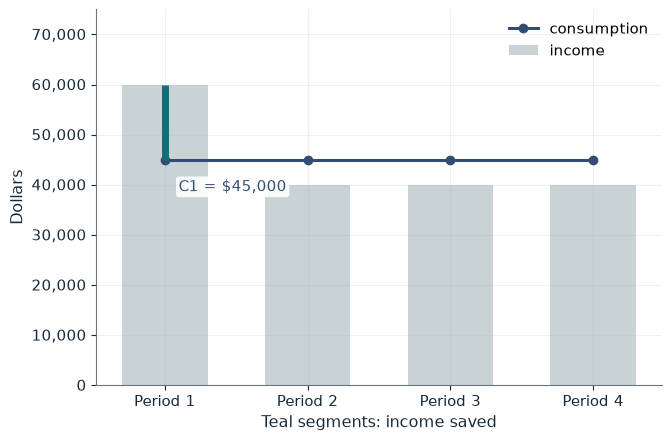

Resources                       $180,000
Smoothed level                  $45,000
Period-1 consumption            $45,000
Change in period-1 consumption  $5,000
Saved in period 1               $15,000
Later consumption per period    $45,000.00

Worked steps:
  1. Resources = 60,000 + 40,000 + 40,000 + 40,000 = 180,000
  2. Smoothed level = 180,000 / 4 = 45,000
  3. Change in C1 = 45,000 - 40,000 = 5,000
  4. Saved in period 1 = 60,000 - 45,000 = 15,000

With a one-period bonus of $20,000, resources are $180,000 and the smoothed level is 180,000 / 4 = 45,000 dollars. Consumption is $45,000 in every period. Period-1 consumption rises by $5,000 and the household saves $15,000 of period-1 income.


In [2]:
show(pih_picture(boost=20_000, kind='one', floor='none'))

Change one input, `kind`, and hold the others at the book's values:

In [3]:
sweep(pih_picture, 'kind', ['one', 'all'], {'boost': 20000, 'floor': 'none'}, ['Period-1 consumption', 'Change in period-1 consumption', 'Saved in period 1'])

kind | Period-1 consumption | Change in period-1 consumption | Saved in period 1
one | $45,000 | $5,000 | $15,000
all | $60,000 | $20,000 | $0


The bonus raises period-1 consumption by only 5,000 dollars and 15,000 is saved; a permanent raise of the same size lifts consumption to 60,000. With a 50,000 dollar need and no borrowing (`floor='50000'`) the household spends 50,000 now, 10,000 more than its old income.

## 2. Ricardian equivalence: a tax cut paid back with interest

The government cuts year-1 taxes by 1,000 dollars and repays the bond at 5 percent.

$$1.05(1{,}000)=1{,}050\text{ dollars}, \qquad \frac{1{,}050}{1.05}=1{,}000\text{ dollars}$$

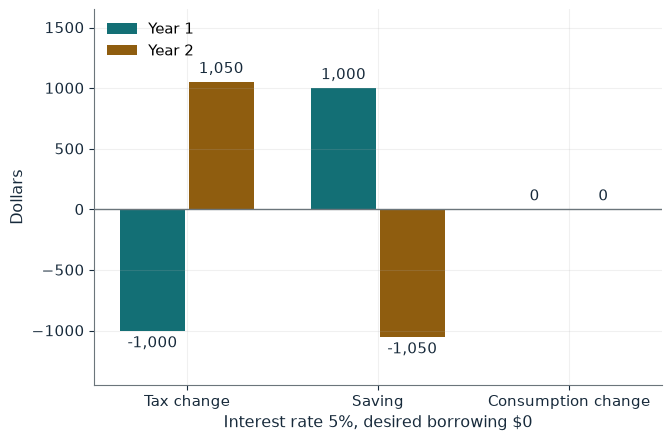

Future tax                         $1,050.00
Present value of future tax        $1,000.00
Year-1 saving                      $1,000.00
Year-1 consumption change          $0.00
Saving with interest               $1,050.00
Remaining year-2 burden            $0.00
Present value of remaining burden  $0.00

Worked steps:
  1. Future tax = 1.05 x 1,000 = 1,050.00
  2. Present value = 1,050.00 / 1.05 = 1,000.00
  3. Saved = 1,000 - 0 = 1,000
  4. Saving grows to 1.05 x 1,000 = 1,050.00
  5. Remaining burden = 1,050.00 - 1,050.00 = 0.00

The 1,000 dollar cut is repaid with a year-2 tax of 1.05 x 1,000 = 1,050.00 dollars, worth $1,000.00 today. Saving $1,000 grows to $1,050.00, leaving $0.00. The household saves the whole cut, the deposit exactly covers the later tax, and consumption is unchanged in both years: Ricardian equivalence holds.


In [4]:
show(ricardian_picture(r=0.05, shift=0))

Change one input, `shift`, and hold the others at the book's values:

In [5]:
sweep(ricardian_picture, 'shift', [0, 400, 800], {'r': 0.05}, ['Year-1 saving', 'Year-1 consumption change', 'Remaining year-2 burden'])

shift | Year-1 saving | Year-1 consumption change | Remaining year-2 burden
0 | $1,000.00 | $0.00 | $0.00
400 | $600.00 | $400.00 | $420.00
800 | $200.00 | $800.00 | $840.00


An unconstrained household saves the whole cut and consumption does not move. A household that wanted to borrow 400 spends 400, saves 600 (630 with interest) and is left with 420 of the later tax, worth 400 today.

## 3. Paradox of thrift: everyone saves, nobody saves more

Consumption is $C=20+0.8Y$ and planned investment is 80.

$$Y=\frac{20+80}{1-0.8}=500, \qquad Y'=\frac{10+80}{1-0.8}=450$$

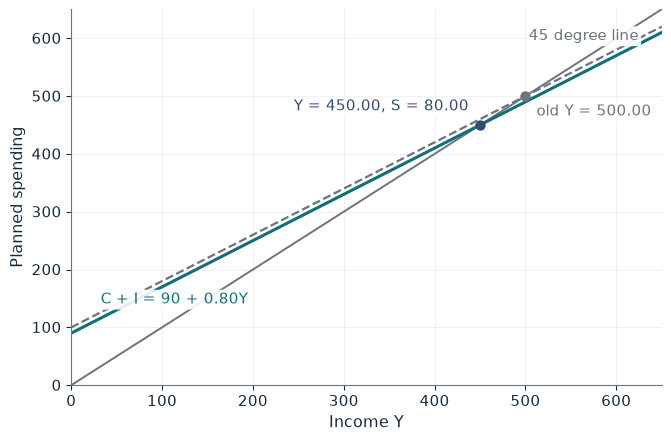

Output Y                          450.00
Consumption C                     370.00
Realized saving S                 80.00
Multiplier                        5.00
Output loss versus a = 20         50.00
Planned saving at the old income  90.00

Worked steps:
  1. Y = (10 + 80) / (1 - 0.80) = 90 / 0.20 = 450.00
  2. C = 10 + 0.80 x 450.00 = 370.00
  3. S = 450.00 - 370.00 = 80.00
  4. Loss = 500.00 - 450.00 = 50.00

Equilibrium output is (10 + 80) / (1 - 0.80) = 450.00, with C = 370.00 and S = 450.00 - 370.00 = 80.00. The multiplier is 1 / 0.20 = 5.00. At the old income 500.00, planned saving would be 500.00 - (10 + 0.80 x 500.00) = 90.00, but output falls by 50.00 and realized saving stays at 80.00, equal to fixed investment.


In [6]:
show(thrift_picture(a=10, c=0.8))

Change one input, `a`, and hold the others at the book's values:

In [7]:
sweep(thrift_picture, 'a', [10, 15, 20], {'c': 0.8}, ['Output Y', 'Consumption C', 'Realized saving S'])

a | Output Y | Consumption C | Realized saving S
10 | 450.00 | 370.00 | 80.00
15 | 475.00 | 395.00 | 80.00
20 | 500.00 | 420.00 | 80.00


Cutting autonomous consumption by 10 lowers output by 50, five times the cut, and realized saving stays at 80 because fixed investment pins it down.

## 4. Balanced-budget multiplier: spend and tax the same amount

Purchases and lump-sum taxes both rise by 40 million dollars and $c=0.75$.

$$\frac{1}{1-0.75}(40)=160\text{ million dollars}, \qquad -\frac{0.75}{1-0.75}(40)=-120\text{ million dollars}$$

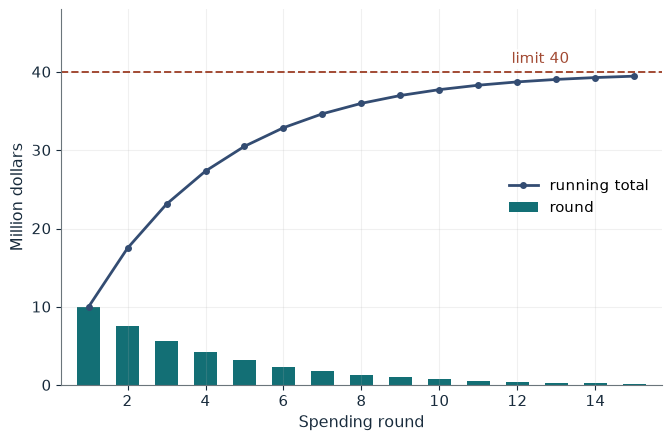

First round                    10.00
Purchases effect               160.00
Tax effect                     -120.00
Net change in output           40.00
Balanced-budget multiplier     1.00
Running total after 15 rounds  39.47

Worked steps:
  1. First round = 40 - 0.75 x 40 = 10.00
  2. Rounds: 10.00, 7.5000, 5.6250, ...
  3. Sum = 10.00 / (1 - 0.75) = 40.00
  4. Purchases effect = 40 / 0.25 = 160.00
  5. Tax effect = -0.75 x 40 / 0.25 = -120.00
  6. Net = 160.00 + (-120.00) = 40.00

Purchases add 40 million and the tax removes 0.75 x 40 = 30.00 of consumption, so the first round is 10.00. The rounds sum to 10.00 / (1 - 0.75) = 40.00. Separately, the purchases effect is 160.00 and the tax effect -120.00, netting to 40.00: the multiplier is 1 at this marginal propensity to consume, as at every other.


In [8]:
show(bbm_picture(c=0.75, delta=40))

Change one input, `c`, and hold the others at the book's values:

In [9]:
sweep(bbm_picture, 'c', [0.5, 0.75, 0.9], {'delta': 40}, ['First round', 'Purchases effect', 'Tax effect', 'Net change in output'])

c | First round | Purchases effect | Tax effect | Net change in output
0.5 | 20.00 | 80.00 | -40.00 | 40.00
0.75 | 10.00 | 160.00 | -120.00 | 40.00
0.9 | 4.00 | 400.00 | -360.00 | 40.00


The first round is 10, the rounds sum to 40, and the two separate effects (160 and -120) net to 40. A higher propensity enlarges both effects but leaves the net at 40: the multiplier is 1.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

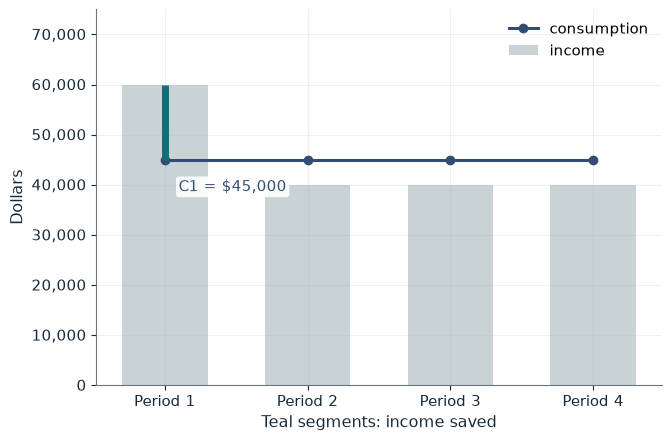

Resources                       $180,000
Smoothed level                  $45,000
Period-1 consumption            $45,000
Change in period-1 consumption  $5,000
Saved in period 1               $15,000
Later consumption per period    $45,000.00

Worked steps:
  1. Resources = 60,000 + 40,000 + 40,000 + 40,000 = 180,000
  2. Smoothed level = 180,000 / 4 = 45,000
  3. Change in C1 = 45,000 - 40,000 = 5,000
  4. Saved in period 1 = 60,000 - 45,000 = 15,000

With a one-period bonus of $20,000, resources are $180,000 and the smoothed level is 180,000 / 4 = 45,000 dollars. Consumption is $45,000 in every period. Period-1 consumption rises by $5,000 and the household saves $15,000 of period-1 income.


In [10]:
show(pih_picture(boost=20_000, kind='one', floor='none'))

## Practice

**1.** If the 20,000 dollar increase is permanent, what is period-1 consumption?

<details><summary>Answer</summary>

Resources are 4 x 60,000 = 240,000, so consumption is 240,000 / 4 = 60,000, a rise of 20,000.

</details>

**2.** With a = 10 and c = 0.8, what is the output loss and realized saving?

<details><summary>Answer</summary>

Y' = 90 / 0.2 = 450, a loss of 500 - 450 = 50; S' = 450 - (10 + 0.8 x 450) = 450 - 370 = 80.

</details>

**3.** At c = 0.9 and a 40 million balanced change, what are the two separate effects?

<details><summary>Answer</summary>

40 / 0.1 = 400 and -0.9 x 40 / 0.1 = -360, so the net is 40.

</details>